# SAM 3D Objects: 3D reconstruction of the vehicles segmented by SAM 3

This notebook takes **one frame** and the **masks produced by the SAM 3 notebook** (`sam3.ipynb`) and reconstructs a **3D model of each car** with **SAM 3D Objects** (Meta).
It does **not** run SAM 3: it only reads the files that notebook wrote in `./sam3_output/` (`frames/`, `masks/`, `tracks.csv`, `run_info.json`).

**Outputs** (in `./sam3d_output/`): for every selected car a Gaussian-splat file (`.ply`), a mesh (`.glb`) when available, previews, and optionally one combined scene.

---

## ⚠️ Hardware requirements (read this first)

According to the official setup guide, SAM 3D Objects needs:

* **Linux, 64-bit**
* **An NVIDIA GPU with at least 32 GB of VRAM** (e.g. A100, H100, L40S, RTX A6000, RTX 5090)

It therefore **does not run on a Mac (Apple Silicon/MPS), on Windows natively, or on small GPUs**.
Run the SAM 3 notebook on your Mac, then copy the `sam3_output` folder to a Linux GPU machine (cloud GPU rental, university cluster, etc.) and run **this** notebook there.

---

## 1. Move the SAM 3 output to the GPU machine

On the machine where you ran the SAM 3 notebook:
```bash
zip -r sam3_output.zip sam3_output
```
Upload `sam3_output.zip` next to this notebook (Cell 2 unzips it automatically), or copy the `sam3_output` folder directly.
If you want higher-quality textures, also upload the original video (see `ORIGINAL_VIDEO_PATH` in Cell 1).

> The SAM 3 notebook must be the **latest version**: older versions did not save `frames/`, `masks/` and the `mask_file` column, so this notebook cannot use their output.

## 2. Create the SAM 3D environment (once, on the Linux GPU machine)

Commands from the official repository (`doc/setup.md`). Run them from the folder that contains this notebook.
Build the environment **on a machine with the GPU attached** (PyTorch3D fails to build otherwise).

```bash
git clone https://github.com/facebookresearch/sam-3d-objects.git
cd sam-3d-objects

# create the environment (use conda instead of mamba if you prefer)
mamba env create -f environments/default.yml
mamba activate sam3d-objects

# PyTorch / CUDA dependencies
export PIP_EXTRA_INDEX_URL="https://pypi.ngc.nvidia.com https://download.pytorch.org/whl/cu121"

# install sam3d-objects and core dependencies
pip install -e '.[dev]'
pip install -e '.[p3d]'      # PyTorch3D needs this 2-step approach

# inference dependencies
export PIP_FIND_LINKS="https://nvidia-kaolin.s3.us-east-2.amazonaws.com/torch-2.5.1_cu121.html"
pip install -e '.[inference]'

# patch for a Hydra fix not yet in the official release
./patching/hydra

# notebook support in this environment
pip install ipykernel matplotlib opencv-python
python -m ipykernel install --user --name sam3d-objects
```

## 3. Download the checkpoints

1. Request access at https://huggingface.co/facebook/sam-3d-objects (gated repository).
2. Log in (`hf auth login`) and download:

```bash
pip install 'huggingface-hub[cli]<1.0'

TAG=hf
hf download \
  --repo-type model \
  --local-dir checkpoints/${TAG}-download \
  --max-workers 1 \
  facebook/sam-3d-objects
mv checkpoints/${TAG}-download/checkpoints checkpoints/${TAG}
rm -rf checkpoints/${TAG}-download
```

## 4. Select the kernel

Open this notebook and choose the **`sam3d-objects`** kernel (Select Kernel → Jupyter Kernel).

## 5. Notes

* Run the cells in order. If you hit a CUDA out-of-memory error, restart the kernel and reconstruct fewer objects (`MAX_OBJECTS`).
* SAM 3D works from a **single image**: occluded or very small cars (few pixels) give poor results. Low-resolution frames (e.g. 640 px wide from the `low` preset of the SAM 3 notebook) reduce quality a lot.
* The SAM 3D model and code are released under the SAM License.

# Cell 1: Settings (the only cell you normally need to edit)

In [1]:
# ---------------- Inputs ----------------
SAM3_OUTPUT_DIR = "./sam3_output"      # folder written by the SAM 3 notebook
SAM3D_REPO = "./sam-3d-objects"        # cloned repository (see setup instructions)
CHECKPOINT_TAG = "hf"                  # checkpoints/<tag>/pipeline.yaml

# ---------------- Which frame / which cars ----------------
FRAME = None            # frame index to use (e.g. 24). None -> the saved frame with the most cars
OBJECT_IDS = None       # list of SAM 3 object ids, e.g. [3, 7]. None -> all cars passing the filters below
MAX_OBJECTS = 5         # reconstruct at most this many cars (largest masks first)
MIN_MASK_AREA_FRAC = 0.002             # ignore masks smaller than this fraction of the image
SKIP_BORDER_TOUCHING = False           # True -> skip cars cut by the image border

# ---------------- Mask / image options ----------------
CLEAN_MASKS = True                     # keep the largest blob and fill small holes
ORIGINAL_VIDEO_PATH = None             # e.g. "input_video.mp4": use the full-resolution frame (masks are upscaled)

# ---------------- Reconstruction / export ----------------
SEED = 42
EXPORT_MESH_FALLBACK = True            # if SAM 3D returns no mesh, build an approximate one from the splats (needs open3d)
MAKE_COMBINED_SCENE = True             # also try to place all cars in one scene
OUTPUT_DIR = "./sam3d_output"
# ------------------------------------------------

# Cell 2: Environment check and imports

In [2]:
import os
import sys
import csv
import json
import gc
import time
import platform
import zipfile
from pathlib import Path

import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image

import torch

# ---- Hardware check ----
print(f"OS: {platform.system()} ({platform.machine()}) | Python {platform.python_version()} | PyTorch {torch.__version__}")
if platform.system() != "Linux":
    print("WARNING: SAM 3D Objects officially supports Linux only.")
if not torch.cuda.is_available():
    raise RuntimeError("No CUDA GPU found. SAM 3D Objects needs an NVIDIA GPU with >= 32 GB VRAM (Linux). "
                       "Run this notebook on a suitable GPU machine.")
props = torch.cuda.get_device_properties(0)
vram = props.total_memory / 1e9
print(f"GPU: {props.name} | VRAM: {vram:.1f} GB")
if vram < 30:
    print("WARNING: less than 32 GB of VRAM. Loading or running the model will probably fail with out-of-memory.")

# ---- Resolve all paths to absolute ones (Cell 4 changes the working directory to the repository) ----
NOTEBOOK_DIR = globals().get("NOTEBOOK_DIR", Path.cwd())    # remembered on re-runs
os.chdir(NOTEBOOK_DIR)
SAM3_DIR = Path(SAM3_OUTPUT_DIR).resolve()
REPO = Path(SAM3D_REPO).resolve()
OUT = Path(OUTPUT_DIR).resolve()
VIDEO_FULL = Path(ORIGINAL_VIDEO_PATH).resolve() if ORIGINAL_VIDEO_PATH else None
OUT.mkdir(parents=True, exist_ok=True)

# ---- Optional: unzip sam3_output.zip if the folder is not there yet ----
zip_candidates = [NOTEBOOK_DIR / "sam3_output.zip", SAM3_DIR.with_suffix(".zip")]
if not SAM3_DIR.exists():
    for z in zip_candidates:
        if z.exists():
            print(f"Unzipping {z} ...")
            with zipfile.ZipFile(z) as zf:
                zf.extractall(SAM3_DIR.parent)
            break

# ---- Check inputs ----
tracks_csv = SAM3_DIR / "tracks.csv"
if not tracks_csv.exists():
    raise FileNotFoundError(f"{tracks_csv} not found. Run the SAM 3 notebook first and copy its output folder here.")

config_path = REPO / "checkpoints" / CHECKPOINT_TAG / "pipeline.yaml"
if not config_path.exists():
    raise FileNotFoundError(f"{config_path} not found. Clone the repository and download the checkpoints (see the setup section).")

# ---- Make the SAM 3D inference code importable ----
sys.path.insert(0, str(REPO / "notebook"))
sys.path.insert(0, str(REPO))
print("Inputs and checkpoints found.")

/home/nizar.nadif/fm/.venv-sam3d/lib/python3.11/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


OS: Linux (x86_64) | Python 3.11.0 | PyTorch 2.5.1+cu121
GPU: NVIDIA GeForce RTX 4090 | VRAM: 25.3 GB
Inputs and checkpoints found.


# Cell 3: Read the SAM 3 output and choose the frame and the cars

Frame 192: 1280x720 px, 14 masks saved

  id prompt    score  area %  border
   8 car        0.71    2.29   False
  17 car        0.72    0.87   False
  19 car        0.72    0.44   False
  11 car        0.83    0.39    True
   2 car        0.96    0.24   False
  25 car        0.71    0.24   False
  23 car        0.71    0.22   False
  21 car        0.75    0.17   False
  22 car        0.70    0.16   False
  20 car        0.75    0.16    True
  13 car        0.70    0.08    True
  26 car        0.72    0.03    True
  12 car        0.76    0.00    True
  24 car        0.80    0.00   False

Selected object ids: [8, 17, 19, 11, 2]


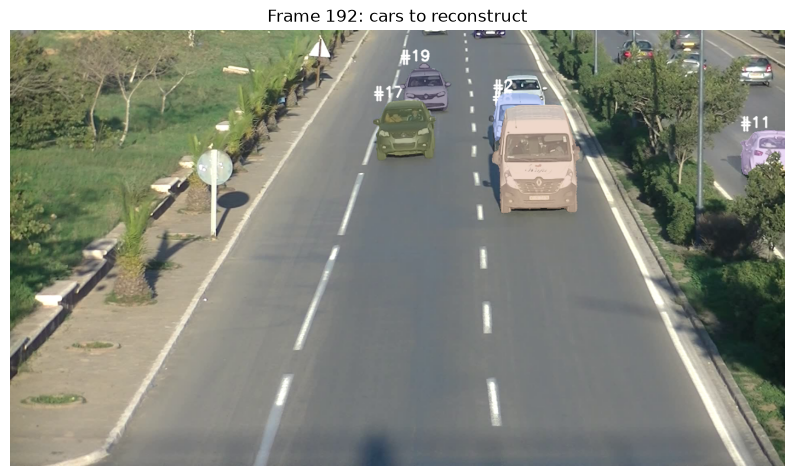

In [3]:
# ---- Read tracks.csv ----
with open(SAM3_DIR / "tracks.csv", newline="") as f:
    rows = list(csv.DictReader(f))
if not rows or "mask_file" not in rows[0]:
    raise RuntimeError("tracks.csv has no 'mask_file' column: re-run the latest version of the SAM 3 notebook.")

run_info = {}
if (SAM3_DIR / "run_info.json").exists():
    run_info = json.load(open(SAM3_DIR / "run_info.json"))

rows = [r for r in rows if r["mask_file"]]          # only frames whose masks were saved
for r in rows:
    r["frame"] = int(r["frame"]); r["object_id"] = int(r["object_id"]); r["score"] = float(r["score"])

# ---- Choose the frame ----
by_frame = {}
for r in rows:
    by_frame.setdefault(r["frame"], []).append(r)
if not by_frame:
    raise RuntimeError("No saved masks found in tracks.csv.")

if FRAME is None:
    FRAME_IDX = max(sorted(by_frame), key=lambda k: len(by_frame[k]))
else:
    if FRAME not in by_frame:
        raise ValueError(f"Frame {FRAME} has no saved masks. Available frames: {sorted(by_frame)[:20]}...")
    FRAME_IDX = FRAME

frame_rows = by_frame[FRAME_IDX]
frame_path = SAM3_DIR / frame_rows[0]["frame_file"]
image_small = np.array(Image.open(frame_path).convert("RGB"))
Hs, Ws = image_small.shape[:2]
print(f"Frame {FRAME_IDX}: {Ws}x{Hs} px, {len(frame_rows)} masks saved")

# ---- Optionally use the full-resolution frame from the original video ----
image = image_small
SCALE_TO_FULL = None
if VIDEO_FULL:
    if not run_info:
        print("run_info.json missing: cannot map the frame to the original video. Using the saved frame.")
    elif not VIDEO_FULL.exists():
        print(f"{VIDEO_FULL} not found. Using the saved frame.")
    else:
        orig_idx = int(run_info["start_frame"] + FRAME_IDX * run_info["interval"])
        cap = cv2.VideoCapture(str(VIDEO_FULL))
        cap.set(cv2.CAP_PROP_POS_FRAMES, orig_idx)
        ok, bgr = cap.read()
        cap.release()
        if ok:
            image = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
            SCALE_TO_FULL = (image.shape[1], image.shape[0])
            print(f"Using full-resolution frame #{orig_idx} from the video: {image.shape[1]}x{image.shape[0]}")
        else:
            print("Could not read that frame from the video. Using the saved frame.")
H, W = image.shape[:2]


def load_mask(mask_file):
    m = np.array(Image.open(SAM3_DIR / mask_file).convert("L")) > 127
    if SCALE_TO_FULL is not None:
        m = cv2.resize(m.astype(np.float32), SCALE_TO_FULL, interpolation=cv2.INTER_LINEAR) > 0.5
    return m


def clean_mask(m):
    """Keep the largest connected blob and fill small holes."""
    m8 = m.astype(np.uint8)
    n, labels, stats, _ = cv2.connectedComponentsWithStats(m8, connectivity=8)
    if n > 2:
        keep = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
        m8 = (labels == keep).astype(np.uint8)
    k = max(3, int(round(min(m.shape) * 0.01)) | 1)
    m8 = cv2.morphologyEx(m8, cv2.MORPH_CLOSE, np.ones((k, k), np.uint8))
    return m8.astype(bool)


# ---- Candidate cars in this frame ----
candidates = []
for r in frame_rows:
    m = load_mask(r["mask_file"])
    area = int(m.sum())
    ys, xs = np.where(m)
    touches = bool(area and (ys.min() == 0 or xs.min() == 0 or ys.max() == H - 1 or xs.max() == W - 1))
    candidates.append({"id": r["object_id"], "prompt": r["prompt"], "score": r["score"], "area": area,
                       "area_frac": area / (H * W), "touches_border": touches, "mask_file": r["mask_file"]})

print(f"\n{'id':>4} {'prompt':<8} {'score':>6} {'area %':>7} {'border':>7}")
for c in sorted(candidates, key=lambda c: -c["area"]):
    print(f"{c['id']:>4} {c['prompt']:<8} {c['score']:>6.2f} {100 * c['area_frac']:>7.2f} {str(c['touches_border']):>7}")

# ---- Select ----
selected = [c for c in candidates if c["area_frac"] >= MIN_MASK_AREA_FRAC]
if SKIP_BORDER_TOUCHING:
    selected = [c for c in selected if not c["touches_border"]]
if OBJECT_IDS is not None:
    selected = [c for c in selected if c["id"] in set(OBJECT_IDS)]
selected = sorted(selected, key=lambda c: -c["area"])[:MAX_OBJECTS]
if not selected:
    raise RuntimeError("No car left after filtering. Relax MIN_MASK_AREA_FRAC / OBJECT_IDS / SKIP_BORDER_TOUCHING.")
print(f"\nSelected object ids: {[c['id'] for c in selected]}")

# ---- Show the selection ----
overlay = image.copy()
rng = np.random.default_rng(0)
for c in selected:
    m = load_mask(c["mask_file"])
    overlay[m] = (0.45 * overlay[m] + 0.55 * rng.integers(60, 255, 3)).astype(np.uint8)
    ys, xs = np.where(m)
    cv2.putText(overlay, f"#{c['id']}", (int(xs.min()), max(15, int(ys.min()) - 5)),
                cv2.FONT_HERSHEY_SIMPLEX, max(0.5, W / 1600), (255, 255, 255), 2, cv2.LINE_AA)
plt.figure(figsize=(10, 6)); plt.imshow(overlay); plt.axis("off"); plt.title(f"Frame {FRAME_IDX}: cars to reconstruct"); plt.show()

# Cell 4: Load SAM 3D Objects (run once)

In [4]:
for _name in ("inference",):
    if _name in globals():
        del globals()[_name]
gc.collect()
torch.cuda.empty_cache()

# The repository code was written to be run from its root folder
os.chdir(REPO)

from inference import Inference

print("Loading SAM 3D Objects (this can take a few minutes)...")
t0 = time.time()
inference = Inference(str(config_path), compile=False)
print(f"Model ready in {time.time() - t0:.0f} s | VRAM in use: {torch.cuda.memory_allocated() / 1e9:.1f} GB")

Warp 1.19.0 initialized:
   CUDA Toolkit 13.4, Driver 13.2
   Devices:
     "cpu"      : "CPU"
     "cuda:0"   : "NVIDIA GeForce RTX 4090" (24 GiB, sm_89, mempool enabled)
   Kernel cache:
     /home/nizar.nadif/.cache/warp/1.19.0


2026-11-04 17:33:36.856 | INFO     | sam3d_objects.pipeline.inference_pipeline:set_attention_backend:17 - GPU name is NVIDIA GeForce RTX 4090


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


2026-11-04 17:33:37.700 | INFO     | sam3d_objects.model.backbone.tdfy_dit.modules.sparse:__from_env:39 - [SPARSE] Backend: spconv, Attention: sdpa
2026-11-04 17:33:41.375 | INFO     | sam3d_objects.model.backbone.tdfy_dit.modules.attention:__from_env:30 - [ATTENTION] Using backend: sdpa


[SPARSE][CONV] spconv algo: auto


2026-11-04 17:33:42.351 | WARNING  | sam3d_objects.data.dataset.tdfy.preprocessor:__post_init__:51 - No rgb pointmap normalizer provided, using scale + shift 
2026-11-04 17:33:42.352 | WARNING  | sam3d_objects.data.dataset.tdfy.preprocessor:__post_init__:51 - No rgb pointmap normalizer provided, using scale + shift 
2026-11-04 17:33:42.386 | WARNING  | sam3d_objects.data.dataset.tdfy.preprocessor:__post_init__:51 - No rgb pointmap normalizer provided, using scale + shift 


Loading SAM 3D Objects (this can take a few minutes)...


/home/nizar.nadif/fm/.venv-sam3d/lib/python3.11/site-packages/moge/model/v1.py:171: UserWarning: The following deprecated/invalid arguments are ignored: {'output_mask': True, 'split_head': True}
  warnings.warn(f"The following deprecated/invalid arguments are ignored: {deprecated_kwargs}")
2026-11-04 17:33:47.621 | WARNING  | sam3d_objects.data.dataset.tdfy.preprocessor:__post_init__:51 - No rgb pointmap normalizer provided, using scale + shift 
2026-11-04 17:33:47.623 | INFO     | sam3d_objects.pipeline.inference_pipeline:__init__:100 - self.device: cuda
2026-11-04 17:33:47.623 | INFO     | sam3d_objects.pipeline.inference_pipeline:__init__:101 - CUDA_VISIBLE_DEVICES: None
2026-11-04 17:33:47.623 | INFO     | sam3d_objects.pipeline.inference_pipeline:__init__:102 - Actually using GPU: 0
2026-11-04 17:33:47.624 | INFO     | sam3d_objects.pipeline.inference_pipeline:init_pose_decoder:297 - Using pose decoder: ScaleShiftInvariant
2026-11-04 17:33:47.624 | INFO     | sam3d_objects.pipelin

Model ready in 30 s | VRAM in use: 13.7 GB


# Cell 5: Reconstruct each selected car

In [5]:
if "inference" not in globals():
    raise RuntimeError("The model was freed after the last reconstruction: re-run Cell 4 first.")


def to_numpy(x):
    return x.detach().cpu().numpy() if hasattr(x, "detach") else np.asarray(x)


def to_jsonable(x):
    try:
        return to_numpy(x).astype(float).tolist()
    except Exception:
        return None


def read_gaussian_ply(path):
    """Minimal reader for the binary Gaussian-splat PLY written by SAM 3D."""
    type_map = {"float": "<f4", "double": "<f8", "uchar": "u1", "int": "<i4", "uint": "<u4"}
    with open(path, "rb") as f:
        props, n = [], 0
        while True:
            line = f.readline().decode().strip()
            if line.startswith("format") and "binary_little_endian" not in line:
                raise RuntimeError("Only binary little-endian PLY files are supported.")
            if line.startswith("element vertex"):
                n = int(line.split()[-1])
            elif line.startswith("property"):
                props.append((line.split()[-1], type_map[line.split()[1]]))
            elif line == "end_header":
                break
        return np.frombuffer(f.read(), dtype=np.dtype(props), count=n)


def export_mesh(output, base):
    """Save a mesh if the SAM 3D output contains one. Returns the saved path or None."""
    import trimesh
    if not isinstance(output, dict):
        return None
    for key in ("glb", "mesh"):
        m = output.get(key)
        if m is None:
            continue
        if isinstance(m, (list, tuple)):
            m = m[0]
        try:
            if hasattr(m, "export"):                                  # trimesh object / scene
                path = f"{base}.glb"; m.export(path); return path
            if hasattr(m, "vertices") and hasattr(m, "faces"):         # raw vertices + faces
                tm = trimesh.Trimesh(vertices=to_numpy(m.vertices), faces=to_numpy(m.faces), process=False)
                path = f"{base}.glb"; tm.export(path); return path
        except Exception as e:
            print(f"   could not export '{key}': {e}")
    return None


results = {}      # object id -> SAM 3D output dict
files = {}        # object id -> dict of saved files
(OUT / "objects").mkdir(exist_ok=True)

first = True
for c in selected:
    oid = c["id"]
    print(f"\n=== Car #{oid} ===")
    mask = load_mask(c["mask_file"])
    if CLEAN_MASKS:
        mask = clean_mask(mask)

    torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    try:
        output = inference(image, mask, seed=SEED)
    except torch.cuda.OutOfMemoryError:
        print("   CUDA out of memory: skipping this car (restart the kernel and use fewer objects).")
        gc.collect(); torch.cuda.empty_cache()
        continue
    except Exception as e:
        print(f"   failed: {type(e).__name__}: {e}")
        gc.collect(); torch.cuda.empty_cache()
        continue

    if first and isinstance(output, dict):
        print(f"   output keys: {list(output.keys())}")
        first = False
    print(f"   done in {time.time() - t0:.0f} s | peak VRAM {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")

    base = str(OUT / "objects" / f"car_{oid:03d}")
    saved = {}

    gs = output["gs"] if isinstance(output, dict) and "gs" in output else None
    if gs is not None:
        gs.save_ply(base + ".ply")
        saved["gaussian_splat"] = base + ".ply"

    mesh_path = export_mesh(output, base)
    if mesh_path:
        saved["mesh"] = mesh_path

    pose = {k: to_jsonable(output[k]) for k in ("translation", "rotation", "scale") if isinstance(output, dict) and k in output}
    with open(base + "_info.json", "w") as f:
        json.dump({"object_id": oid, "frame": FRAME_IDX, "seed": SEED, "pose": pose, "files": saved}, f, indent=2)

    Image.fromarray(mask.astype(np.uint8) * 255).save(base + "_mask.png")
    results[oid] = output
    files[oid] = saved
    print("   saved:", {k: Path(v).name for k, v in saved.items()})

print(f"\nReconstructed {len(results)}/{len(selected)} cars")

# Free the model: the next cells only need `results` and the saved files.
# To reconstruct more cars, re-run Cell 4 first.
del inference
gc.collect()
torch.cuda.empty_cache()
print(f"Model freed | VRAM in use: {torch.cuda.memory_allocated() / 1e9:.1f} GB")



=== Car #8 ===


2026-11-04 17:34:12.907 | INFO     | sam3d_objects.pipeline.inference_pipeline:sample_sparse_structure:664 - Sampling sparse structure: inference_steps=25, strength=7, interval=[0, 500], rescale_t=3, cfg_strength_pm=0.0
2026-11-04 17:34:12.908 | INFO     | sam3d_objects.pipeline.inference_pipeline:get_condition_input:633 - Running condition embedder ...
2026-11-04 17:34:13.014 | INFO     | sam3d_objects.pipeline.inference_pipeline:get_condition_input:637 - Condition embedder finishes!
2026-11-04 17:34:16.643 | INFO     | sam3d_objects.pipeline.inference_pipeline:sample_sparse_structure:714 - Downsampled coords from 10378 to 10257
2026-11-04 17:34:16.658 | INFO     | sam3d_objects.pipeline.inference_pipeline_pointmap:run:437 - Rescaling scale by 1 after downsampling
2026-11-04 17:34:16.659 | INFO     | sam3d_objects.pipeline.inference_pipeline:sample_slat:744 - Sampling sparse latent: inference_steps=25, strength=1, interval=[0, 500], rescale_t=1
2026-11-04 17:34:16.659 | INFO     | sam

   output keys: ['6drotation_normalized', 'scale', 'shape', 'translation', 'translation_scale', 'coords_original', 'coords', 'downsample_factor', 'rotation', 'mesh', 'gaussian', 'glb', 'gs', 'pointmap', 'pointmap_colors']
   done in 10 s | peak VRAM 18.8 GB


2026-11-04 17:34:23.678 | INFO     | sam3d_objects.pipeline.inference_pipeline:sample_sparse_structure:664 - Sampling sparse structure: inference_steps=25, strength=7, interval=[0, 500], rescale_t=3, cfg_strength_pm=0.0
2026-11-04 17:34:23.679 | INFO     | sam3d_objects.pipeline.inference_pipeline:get_condition_input:633 - Running condition embedder ...


   saved: {'gaussian_splat': 'car_008.ply', 'mesh': 'car_008.glb'}

=== Car #17 ===


2026-11-04 17:34:23.761 | INFO     | sam3d_objects.pipeline.inference_pipeline:get_condition_input:637 - Condition embedder finishes!
2026-11-04 17:34:27.387 | INFO     | sam3d_objects.pipeline.inference_pipeline:sample_sparse_structure:714 - Downsampled coords from 9741 to 9602
2026-11-04 17:34:27.392 | INFO     | sam3d_objects.pipeline.inference_pipeline_pointmap:run:437 - Rescaling scale by 1 after downsampling
2026-11-04 17:34:27.393 | INFO     | sam3d_objects.pipeline.inference_pipeline:sample_slat:744 - Sampling sparse latent: inference_steps=25, strength=1, interval=[0, 500], rescale_t=1
2026-11-04 17:34:27.393 | INFO     | sam3d_objects.pipeline.inference_pipeline:get_condition_input:633 - Running condition embedder ...
2026-11-04 17:34:27.465 | INFO     | sam3d_objects.pipeline.inference_pipeline:get_condition_input:637 - Condition embedder finishes!
2026-11-04 17:34:30.242 | INFO     | sam3d_objects.pipeline.inference_pipeline:decode_slat:606 - Decoding sparse latent...
2026-

... (9 outputs left out)

2026-11-04 17:34:46.411 | INFO     | sam3d_objects.pipeline.inference_pipeline:sample_sparse_structure:664 - Sampling sparse structure: inference_steps=25, strength=7, interval=[0, 500], rescale_t=3, cfg_strength_pm=0.0
2026-11-04 17:34:46.412 | INFO     | sam3d_objects.pipeline.inference_pipeline:get_condition_input:633 - Running condition embedder ...


   saved: {'gaussian_splat': 'car_011.ply', 'mesh': 'car_011.glb'}

=== Car #2 ===


2026-11-04 17:34:46.495 | INFO     | sam3d_objects.pipeline.inference_pipeline:get_condition_input:637 - Condition embedder finishes!
2026-11-04 17:34:50.118 | INFO     | sam3d_objects.pipeline.inference_pipeline:sample_sparse_structure:714 - Downsampled coords from 12129 to 11841
2026-11-04 17:34:50.124 | INFO     | sam3d_objects.pipeline.inference_pipeline_pointmap:run:437 - Rescaling scale by 1 after downsampling
2026-11-04 17:34:50.125 | INFO     | sam3d_objects.pipeline.inference_pipeline:sample_slat:744 - Sampling sparse latent: inference_steps=25, strength=1, interval=[0, 500], rescale_t=1
2026-11-04 17:34:50.125 | INFO     | sam3d_objects.pipeline.inference_pipeline:get_condition_input:633 - Running condition embedder ...
2026-11-04 17:34:50.199 | INFO     | sam3d_objects.pipeline.inference_pipeline:get_condition_input:637 - Condition embedder finishes!
2026-11-04 17:34:53.054 | INFO     | sam3d_objects.pipeline.inference_pipeline:decode_slat:606 - Decoding sparse latent...
202

   done in 7 s | peak VRAM 19.1 GB
   saved: {'gaussian_splat': 'car_002.ply', 'mesh': 'car_002.glb'}

Reconstructed 5/5 cars


# Cell 6 (optional): Approximate mesh from the splats, if SAM 3D returned no mesh

In [6]:
if EXPORT_MESH_FALLBACK and results:
    missing = [oid for oid in results if "mesh" not in files[oid] and "gaussian_splat" in files[oid]]
    if missing:
        try:
            import open3d as o3d
        except ImportError:
            print("open3d is not installed (pip install open3d). Skipping the fallback mesh.")
        else:
            C0 = 0.28209479177387814      # spherical-harmonics constant for the DC color term
            for oid in missing:
                path = files[oid]["gaussian_splat"]
                data = read_gaussian_ply(path)
                n = len(data)
                xyz = np.stack([data["x"], data["y"], data["z"]], 1).astype(np.float64)
                rgb = np.clip(0.5 + C0 * np.stack([data["f_dc_0"], data["f_dc_1"], data["f_dc_2"]], 1), 0, 1)
                keep = 1 / (1 + np.exp(-data["opacity"])) > 0.3 if "opacity" in data.dtype.names else np.ones(n, bool)
                pcd = o3d.geometry.PointCloud()
                pcd.points = o3d.utility.Vector3dVector(xyz[keep])
                pcd.colors = o3d.utility.Vector3dVector(rgb[keep])
                pcd.estimate_normals()
                mesh, dens = o3d.geometry.TriangleMesh.create_from_point_cloud_poisson(pcd, depth=8)
                mesh.remove_vertices_by_mask(np.asarray(dens) < np.quantile(np.asarray(dens), 0.02))
                out_path = str(Path(path).with_name(Path(path).stem + "_approx_mesh.ply"))
                o3d.io.write_triangle_mesh(out_path, mesh)
                files[oid]["approx_mesh"] = out_path
                print(f"Car #{oid}: approximate colored mesh saved ({len(mesh.triangles):,} triangles): {Path(out_path).name}")
    else:
        print("All cars already have a mesh.")

All cars already have a mesh.


# Cell 7: Preview

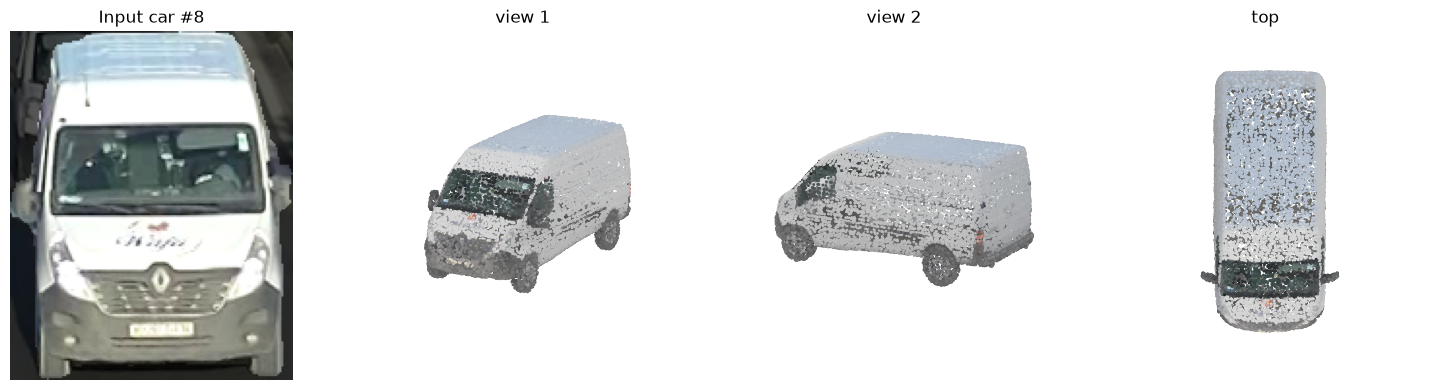

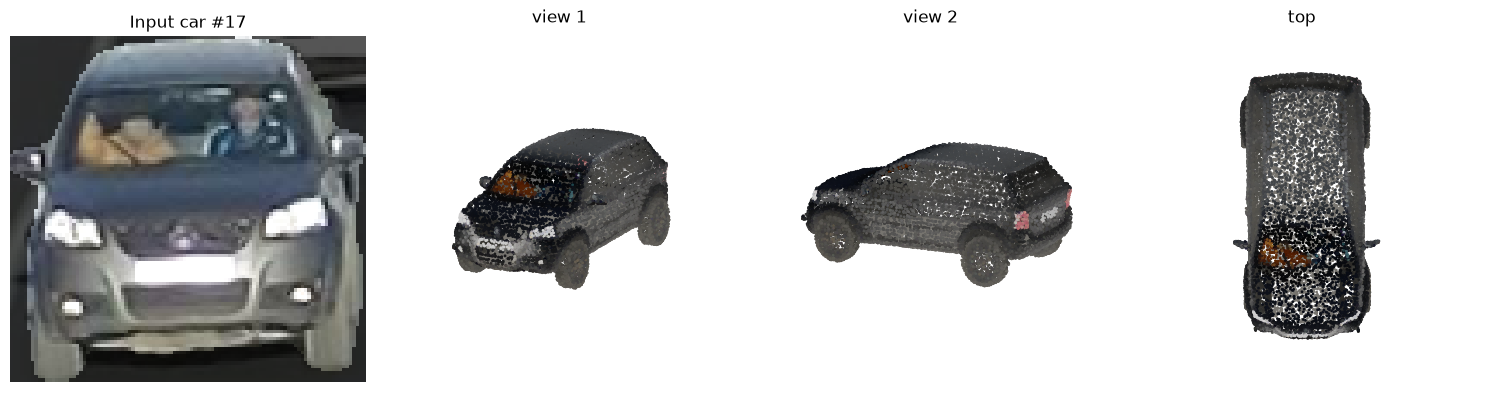

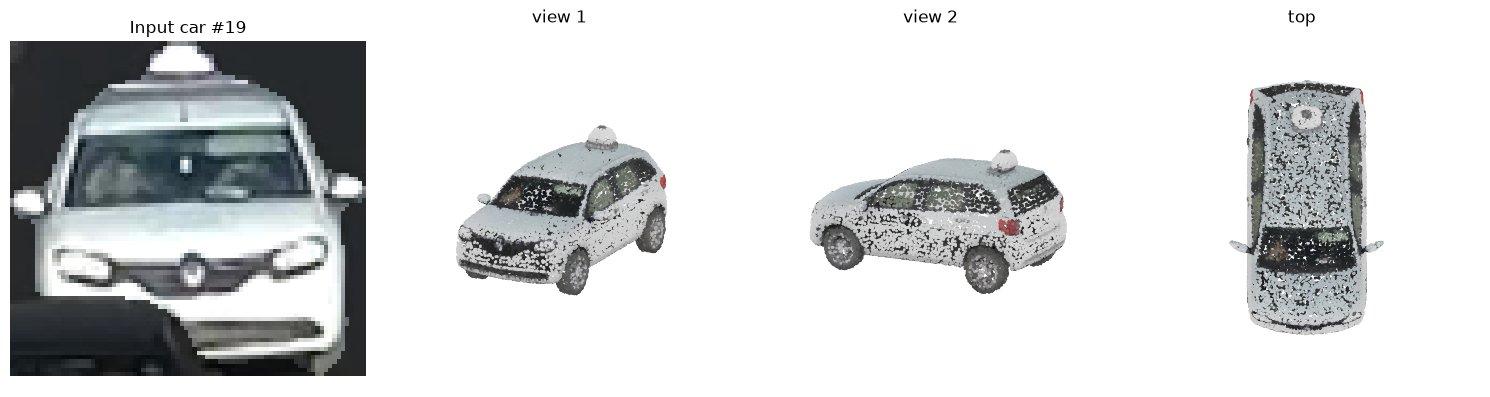

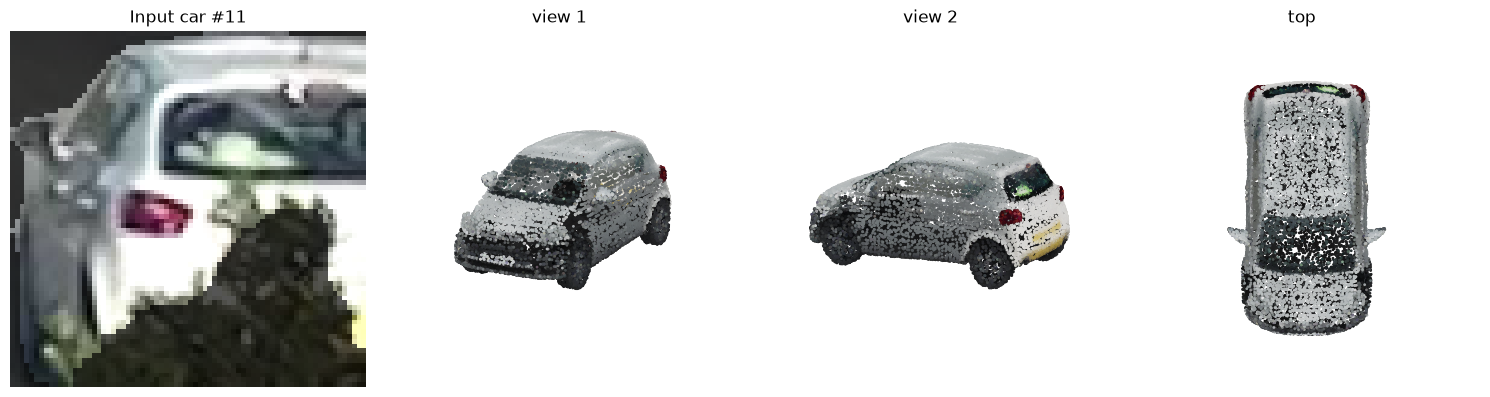

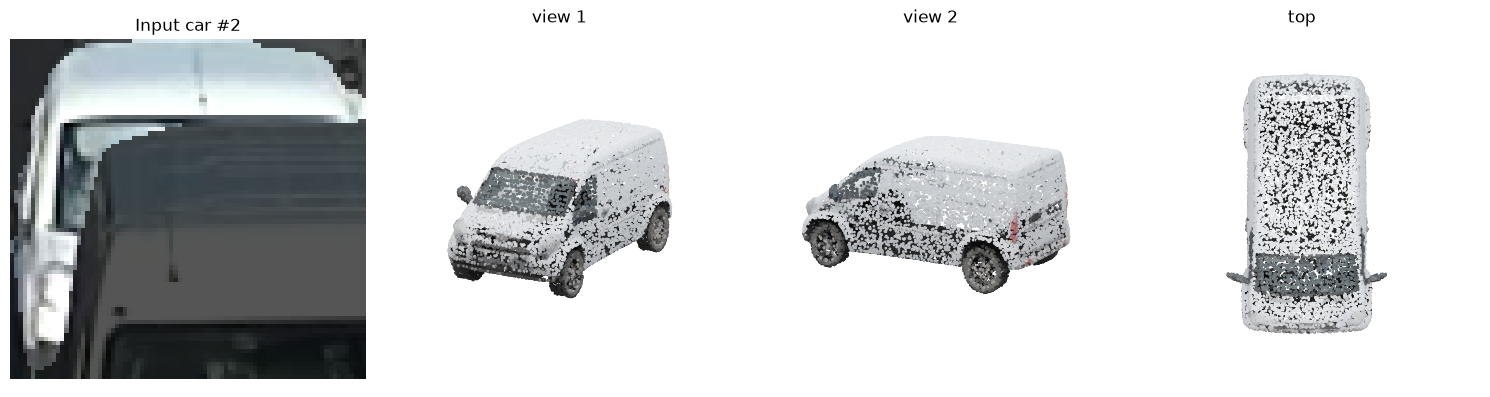

Note: the preview uses raw SAM 3D coordinates; an object can look rotated or upside down. Open the .ply files in a Gaussian-splat viewer (e.g. SuperSplat) and the .glb files in Blender/any 3D viewer for a faithful view.


In [7]:
PREVIEW_POINTS = 30000
C0 = 0.28209479177387814

for oid, saved in files.items():
    if "gaussian_splat" not in saved:
        continue
    d = read_gaussian_ply(saved["gaussian_splat"])
    names = d.dtype.names
    xyz = np.stack([d["x"], d["y"], d["z"]], 1)
    rgb = np.clip(0.5 + C0 * np.stack([d["f_dc_0"], d["f_dc_1"], d["f_dc_2"]], 1), 0, 1) if "f_dc_0" in names else np.full((len(xyz), 3), 0.5)
    if "opacity" in names:
        vis = 1 / (1 + np.exp(-d["opacity"])) > 0.3
        xyz, rgb = xyz[vis], rgb[vis]
    if len(xyz) > PREVIEW_POINTS:
        sel = np.random.default_rng(0).choice(len(xyz), PREVIEW_POINTS, replace=False)
        xyz, rgb = xyz[sel], rgb[sel]

    mask = np.array(Image.open(OUT / "objects" / f"car_{oid:03d}_mask.png").convert("L")) > 127
    ys, xs = np.where(mask)
    crop = image[ys.min():ys.max() + 1, xs.min():xs.max() + 1].copy()
    crop[~mask[ys.min():ys.max() + 1, xs.min():xs.max() + 1]] //= 3      # dim the background

    fig = plt.figure(figsize=(15, 4))
    ax = fig.add_subplot(1, 4, 1); ax.imshow(crop); ax.set_title(f"Input car #{oid}"); ax.axis("off")
    for i, (elev, azim, title) in enumerate([(15, -60, "view 1"), (15, 30, "view 2"), (80, -90, "top")], start=2):
        ax = fig.add_subplot(1, 4, i, projection="3d")
        ax.scatter(xyz[:, 0], xyz[:, 1], xyz[:, 2], c=rgb, s=1, depthshade=False)
        ax.view_init(elev=elev, azim=azim); ax.set_title(title); ax.set_axis_off()
        ax.set_box_aspect(np.ptp(xyz, axis=0) + 1e-9)
    plt.tight_layout(); plt.show()

print("Note: the preview uses raw SAM 3D coordinates; an object can look rotated or upside down. "
      "Open the .ply files in a Gaussian-splat viewer (e.g. SuperSplat) and the .glb files in Blender/any 3D viewer for a faithful view.")

# Cell 8 (optional): Combine all cars in one scene

In [8]:
if MAKE_COMBINED_SCENE and len(results) > 1:
    try:
        from inference import make_scene          # helper used in the repository's multi-object demo
        scene = make_scene(*results.values())
        scene_path = str(OUT / f"scene_frame_{FRAME_IDX:05d}.ply")
        scene.save_ply(scene_path)
        print(f"Combined scene saved: {scene_path}")
    except Exception as e:
        print(f"Could not build the combined scene ({type(e).__name__}: {e}).")
        print("Compare with notebook/demo_multi_object.ipynb in the SAM 3D repository: the helper's name or signature may differ in your version.")
else:
    print("Skipped (MAKE_COMBINED_SCENE is False or fewer than 2 cars were reconstructed).")

Combined scene saved: /home/nizar.nadif/fm/fm-alessio/sam3d_output/scene_frame_00192.ply


# Cell 9: Summary and download

In [9]:
import shutil

print("Saved files:")
for oid, saved in files.items():
    for kind, path in saved.items():
        print(f"  car #{oid:<3} {kind:<15} {Path(path).relative_to(OUT)}")

archive = shutil.make_archive(str(OUT.parent / "sam3d_output"), "zip", OUT)
print(f"\nEverything is zipped here: {archive}")

Saved files:
  car #8   gaussian_splat  objects/car_008.ply
  car #8   mesh            objects/car_008.glb
  car #17  gaussian_splat  objects/car_017.ply
  car #17  mesh            objects/car_017.glb
  car #19  gaussian_splat  objects/car_019.ply
  car #19  mesh            objects/car_019.glb
  car #11  gaussian_splat  objects/car_011.ply
  car #11  mesh            objects/car_011.glb
  car #2   gaussian_splat  objects/car_002.ply
  car #2   mesh            objects/car_002.glb

Everything is zipped here: /home/nizar.nadif/fm/fm-alessio/sam3d_output.zip


# Cell 10 (optional): Free GPU memory

In [10]:
for _name in ("inference", "results"):
    if _name in globals():
        del globals()[_name]
gc.collect()
torch.cuda.empty_cache()
print(f"VRAM in use: {torch.cuda.memory_allocated() / 1e9:.1f} GB")

VRAM in use: 0.2 GB
